# 01 - RouterBench EDA

EDA only: nothing in the pipeline imports from this notebook. Requires `make data`.

Questions:
1. Which model is best per source benchmark?
2. How often is the cheapest model already correct?
3. What fraction of prompts does no model solve?
4. How large is the cost spread across models?

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from router.config import PROJECT_ROOT
from router.data import load_outcomes, load_prompts

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
FIG_DIR = PROJECT_ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_outcomes()
prompts = load_prompts()
print(
    f"{len(df):,} outcome rows | {df.prompt_id.nunique():,} prompts | {df.model.nunique()} models"
)

401,467 outcome rows | 36,497 prompts | 11 models


## 0. Overview: prompts per source, and how quality is graded

In [2]:
graded = df.assign(is_binary=df.quality.isin([0.0, 1.0]))
overview = graded.groupby("source").agg(
    n_prompts=("prompt_id", "nunique"),
    n_eval_names=("eval_name", "nunique"),
    frac_cells_binary=("is_binary", "mean"),
    n_distinct_quality=("quality", "nunique"),
)
overview.sort_values("n_prompts", ascending=False).round(3)

,n_prompts,n_eval_names,frac_cells_binary,n_distinct_quality
source,,,,
mmlu,14042,57,1.000,2
hellaswag,10042,1,1.000,2
gsm8k,7450,1,0.008,5
misc,1719,21,0.843,5
arc_challenge,1470,1,1.000,2
winogrande,1267,1,1.000,2
mbpp,427,1,1.000,2
mtbench,80,3,0.316,10


In [3]:
# Sources whose quality is NOT purely 0/1 -> "correct" is ill-defined there.
BINARY_SOURCES = sorted(overview.index[overview.frac_cells_binary == 1.0])
GRADED_SOURCES = sorted(overview.index[overview.frac_cells_binary < 1.0])
print("binary :", BINARY_SOURCES)
print("graded :", GRADED_SOURCES)
df[df.source.isin(GRADED_SOURCES)].groupby("source").quality.value_counts().unstack(fill_value=0)

binary : ['arc_challenge', 'hellaswag', 'mbpp', 'mmlu', 'winogrande']
graded : ['gsm8k', 'misc', 'mtbench']


quality,0.00,0.10,0.20,0.25,0.30,0.40,0.50,0.60,0.70,0.75,0.80,0.90,1.00
source,,,,,,,,,,,,,
gsm8k,331,0,0,24171,0,0,12972,0,0,44190,0,0,286
misc,10272,0,0,450,0,0,409,0,0,2111,0,0,5667
mtbench,0,177,68,0,42,41,37,3,47,0,61,126,278


## 1. Best model per source (mean quality)

In [4]:
mean_q = df.pivot_table(index="source", columns="model", values="quality", aggfunc="mean")
mean_q.loc["ALL (prompt-weighted)"] = df.groupby("model").quality.mean()
mean_q.round(3).T

source,arc_challenge,gsm8k,hellaswag,mbpp,misc,mmlu,mtbench,winogrande,ALL (prompt-weighted)
model,,,,,,,,,
WizardLM/WizardLM-13B-V1.2,0.610,0.506,0.334,0.370,0.348,0.447,0.545,0.507,0.431
claude-instant-v1,0.803,0.627,0.585,0.604,0.374,0.596,0.629,0.620,0.598
claude-v1,0.869,0.651,0.569,0.597,0.460,0.657,0.649,0.660,0.630
claude-v2,0.869,0.663,0.624,0.642,0.430,0.628,0.675,0.661,0.636
gpt-3.5-turbo-1106,0.831,0.605,0.587,0.653,0.484,0.647,0.689,0.579,0.619
gpt-4-1106-preview,0.962,0.659,0.840,0.686,0.564,0.812,0.806,0.819,0.781
meta/code-llama-instruct-34b-chat,0.373,0.457,0.208,0.518,0.303,0.005,0.528,0.384,0.202
meta/llama-2-70b-chat,0.734,0.523,0.526,0.330,0.329,0.027,0.586,0.482,0.329
mistralai/mistral-7b-chat,0.388,0.412,0.255,0.344,0.322,0.254,0.524,0.524,0.306


In [5]:
best = pd.DataFrame(
    {
        "best_model": mean_q.idxmax(axis=1),
        "best_mean_quality": mean_q.max(axis=1),
        "runner_up": mean_q.apply(lambda r: r.nlargest(2).index[1], axis=1),
        "gap_to_runner_up": mean_q.apply(
            lambda r: r.nlargest(2).iloc[0] - r.nlargest(2).iloc[1], axis=1
        ),
    }
)
best.round(3)

,best_model,best_mean_quality,runner_up,gap_to_runner_up
source,,,,
arc_challenge,gpt-4-1106-preview,0.962,claude-v1,0.093
gsm8k,claude-v2,0.663,gpt-4-1106-preview,0.004
hellaswag,gpt-4-1106-preview,0.840,zero-one-ai/Yi-34B-Chat,0.097
mbpp,gpt-4-1106-preview,0.686,gpt-3.5-turbo-1106,0.033
misc,gpt-4-1106-preview,0.564,gpt-3.5-turbo-1106,0.080
mmlu,gpt-4-1106-preview,0.812,zero-one-ai/Yi-34B-Chat,0.153
mtbench,gpt-4-1106-preview,0.806,gpt-3.5-turbo-1106,0.118
winogrande,gpt-4-1106-preview,0.819,claude-v2,0.159
ALL (prompt-weighted),gpt-4-1106-preview,0.781,zero-one-ai/Yi-34B-Chat,0.134


## 2. How often is the cheapest model already correct?

Two definitions of "cheapest": the **globally** cheapest model (lowest mean cost) and the **per-prompt** cheapest model (costs depend on token counts, so this can vary).

- (a) Binary sources only: P(quality == 1).
- (b) All sources, threshold-free: P(cheapest model's quality == best quality any model achieved on that prompt).

In [6]:
mean_cost = df.groupby("model").cost.mean().sort_values()
global_cheapest = mean_cost.index[0]

max_q = df.groupby("prompt_id").quality.transform("max")
df = df.assign(max_q=max_q, matches_best=df.quality == max_q)
per_prompt_cheapest = df.loc[df.groupby("prompt_id").cost.idxmin()]
global_cheapest_rows = df[df.model == global_cheapest]

print("globally cheapest model:", global_cheapest)
print("per-prompt cheapest model counts:")
print(per_prompt_cheapest.model.value_counts().to_string())

globally cheapest model: mistralai/mistral-7b-chat
per-prompt cheapest model counts:
model
mistralai/mistral-7b-chat            36320
WizardLM/WizardLM-13B-V1.2             166
mistralai/mixtral-8x7b-chat              5
claude-instant-v1                        3
meta/code-llama-instruct-34b-chat        2
zero-one-ai/Yi-34B-Chat                  1


In [7]:
def cheapest_summary(rows: pd.DataFrame) -> pd.DataFrame:
    by_src = rows.groupby("source").agg(
        p_correct=("quality", lambda q: (q == 1.0).mean()),
        p_matches_best=("matches_best", "mean"),
    )
    by_src.loc[by_src.index.isin(GRADED_SOURCES), "p_correct"] = float("nan")
    binary = rows[rows.source.isin(BINARY_SOURCES)]
    by_src.loc["ALL binary sources"] = [(binary.quality == 1.0).mean(), binary.matches_best.mean()]
    by_src.loc["ALL sources"] = [float("nan"), rows.matches_best.mean()]
    return by_src


pd.concat(
    {
        f"global cheapest ({global_cheapest})": cheapest_summary(global_cheapest_rows),
        "per-prompt cheapest": cheapest_summary(per_prompt_cheapest),
    },
    axis=1,
).round(3)

global cheapest (mistralai/mistral-7b-chat)                per-prompt cheapest               
                                                     p_correct p_matches_best           p_correct p_matches_best
source                                                                                                          
arc_challenge                                            0.388          0.397               0.388          0.397
gsm8k                                                      NaN          0.287                 NaN          0.290
hellaswag                                                0.255          0.279               0.255          0.279
mbpp                                                     0.344          0.478               0.354          0.487
misc                                                       NaN          0.448                 NaN          0.450
mmlu                                                     0.254          0.299               0.254          0.299
mtbench                                                    NaN          0.200                 NaN          0.200
winogrande                                               0.524          0.524               0.524          0.524
ALL binary sources                                       0.276          0.310               0.276          0.311
ALL sources                                                NaN          0.312                 NaN          0.313

## 3. What fraction of prompts does NO model solve?

Threshold-free: best quality across all 11 models is exactly 0. For binary sources this means "no model correct".

In [8]:
per_prompt = df.groupby("prompt_id").agg(source=("source", "first"), max_q=("quality", "max"))
unsolved = per_prompt.groupby("source").max_q.agg(
    n_prompts="size",
    frac_unsolved=lambda q: (q == 0).mean(),
    frac_some_model_perfect=lambda q: (q == 1).mean(),
)
unsolved.loc["ALL"] = [
    len(per_prompt),
    (per_prompt.max_q == 0).mean(),
    (per_prompt.max_q == 1).mean(),
]
unsolved.round(3)

,n_prompts,frac_unsolved,frac_some_model_perfect
source,,,
arc_challenge,1470.0,0.010,0.990
gsm8k,7450.0,0.000,0.034
hellaswag,10042.0,0.024,0.976
mbpp,427.0,0.133,0.867
misc,1719.0,0.210,0.733
mmlu,14042.0,0.045,0.955
mtbench,80.0,0.000,0.788
winogrande,1267.0,0.000,1.000
ALL,36497.0,0.036,0.764


## 4. Cost spread across models

In [9]:
cost_tbl = (
    df.groupby("model")
    .agg(
        mean_cost=("cost", "mean"),
        median_cost=("cost", "median"),
        mean_quality=("quality", "mean"),
    )
    .sort_values("mean_cost")
)
cost_tbl["cost_x_vs_cheapest"] = cost_tbl.mean_cost / cost_tbl.mean_cost.min()
cost_tbl.round({"mean_cost": 6, "median_cost": 6, "mean_quality": 3, "cost_x_vs_cheapest": 1})

,mean_cost,median_cost,mean_quality,cost_x_vs_cheapest
model,,,,
mistralai/mistral-7b-chat,0.000046,0.000037,0.306,1.0
WizardLM/WizardLM-13B-V1.2,0.000073,0.000056,0.431,1.6
mistralai/mixtral-8x7b-chat,0.000135,0.000113,0.547,2.9
meta/code-llama-instruct-34b-chat,0.000172,0.000140,0.202,3.8
zero-one-ai/Yi-34B-Chat,0.000186,0.000148,0.647,4.1
meta/llama-2-70b-chat,0.000203,0.000172,0.329,4.4
claude-instant-v1,0.000233,0.000152,0.598,5.1
gpt-3.5-turbo-1106,0.000243,0.000188,0.619,5.3
claude-v1,0.002145,0.001528,0.630,46.9


In [10]:
ratio = df.groupby("prompt_id").cost.agg(lambda c: c.max() / c.min())
print("per-prompt cost ratio (most expensive / cheapest model):")
print(ratio.describe(percentiles=[0.05, 0.5, 0.95]).round(1).to_string())
print("\ntotal cost to run ALL prompts through each model (USD):")
print(df.groupby("model").cost.sum().sort_values().round(2).to_string())

per-prompt cost ratio (most expensive / cheapest model):
count    36497.0
mean        64.7
std         37.1
min         30.2
5%          50.2
50%         50.7
95%        119.1
max       1525.7

total cost to run ALL prompts through each model (USD):
model
mistralai/mistral-7b-chat              1.67
WizardLM/WizardLM-13B-V1.2             2.66
mistralai/mixtral-8x7b-chat            4.91
meta/code-llama-instruct-34b-chat      6.28
zero-one-ai/Yi-34B-Chat                6.77
meta/llama-2-70b-chat                  7.40
claude-instant-v1                      8.50
gpt-3.5-turbo-1106                     8.88
claude-v1                             78.27
claude-v2                             88.27
gpt-4-1106-preview                   120.18


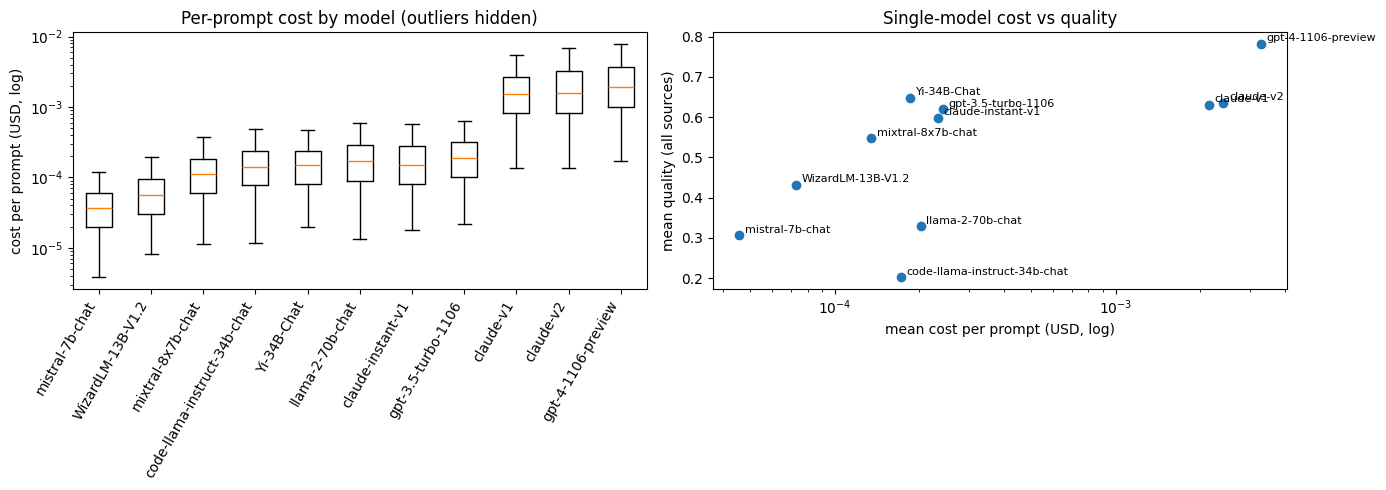

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = cost_tbl.index.tolist()
axes[0].boxplot([df.loc[df.model == m, "cost"] for m in order], showfliers=False)
axes[0].set_xticks(
    range(1, len(order) + 1), [m.split("/")[-1] for m in order], rotation=60, ha="right"
)
axes[0].set_yscale("log")
axes[0].set_ylabel("cost per prompt (USD, log)")
axes[0].set_title("Per-prompt cost by model (outliers hidden)")

axes[1].scatter(cost_tbl.mean_cost, cost_tbl.mean_quality)
for m, r in cost_tbl.iterrows():
    axes[1].annotate(
        m.split("/")[-1],
        (r.mean_cost, r.mean_quality),
        fontsize=8,
        xytext=(4, 2),
        textcoords="offset points",
    )
axes[1].set_xscale("log")
axes[1].set_xlabel("mean cost per prompt (USD, log)")
axes[1].set_ylabel("mean quality (all sources)")
axes[1].set_title("Single-model cost vs quality")

fig.tight_layout()
fig.savefig(FIG_DIR / "eda_cost_quality.png", dpi=120)
plt.show()

## 5. Data-quality checks relevant to M1 (splits)

In [12]:
dup = prompts[prompts.prompt.duplicated(keep=False)]
print(f"prompts with exact-duplicate text: {len(dup)} rows, {dup.prompt.nunique()} distinct texts")
print(dup.groupby("eval_name").size().to_string())

conflict = (
    df[df.prompt_id.isin(dup.prompt_id)]
    .merge(prompts[["prompt_id", "prompt"]], on="prompt_id")
    .groupby(["prompt", "model"])
    .quality.nunique()
)
print(
    "(duplicate text, model) pairs with DIFFERENT quality labels:",
    f"{(conflict > 1).sum()} of {len(conflict)}",
)

lengths = prompts.prompt.str.len()
print("\nprompt length (chars) by source:")
print(lengths.groupby(prompts.source).describe(percentiles=[0.5]).round(0).to_string())

prompts with exact-duplicate text: 32 rows, 16 distinct texts
eval_name
abstract2title                          2
bias_detection                          2
chinese-remainder-theorem               2
chinese_ancient_masterpieces_dynasty    2
chinese_famous_novel                    2
consensus_summary                       8
mbpp                                    4
mmlu-clinical-knowledge                 2
mmlu-college-medicine                   2
mmlu-high-school-psychology             4
mmlu-public-relations                   2
(duplicate text, model) pairs with DIFFERENT quality labels: 15 of 176

prompt length (chars) by source:
                 count    mean    std    min     50%     max
source                                                      
arc_challenge   1470.0   352.0  120.0  150.0   332.0  1008.0
gsm8k           7450.0  1123.0   94.0  931.0  1106.0  1874.0
hellaswag      10042.0   890.0  322.0  226.0  1005.0  1639.0
mbpp             427.0    93.0   40.0   39.0    82.0   4

## 6. Label-noise check: degenerate responses on MMLU

Llama-2-70B and Code-Llama score far below chance (0.25) on 4-way MMLU. Inspect the raw responses (dropped from the tidy table) to see whether this is ability or a generation/format failure.

In [13]:
from router.data import load_raw

raw = load_raw(PROJECT_ROOT / "data/raw/routerbench_0shot.pkl")
mmlu_raw = raw[raw.eval_name.str.startswith("mmlu-")]
models = sorted(df.model.unique())

rows = []
for m in models:
    resp = mmlu_raw[m + "|model_response"].astype(str)
    rows.append(
        {
            "model": m,
            "mmlu_mean_quality": mmlu_raw[m].astype(float).mean(),
            "most_common_response": resp.value_counts().index[0][:40],
            "frac_most_common": resp.value_counts(normalize=True).iloc[0],
        }
    )
pd.DataFrame(rows).set_index("model").round(3)

,mmlu_mean_quality,most_common_response,frac_most_common
model,,,
WizardLM/WizardLM-13B-V1.2,0.447,['\nB'],0.440
claude-instant-v1,0.596,['C'],0.417
claude-v1,0.657,['C'],0.368
claude-v2,0.628,['C'],0.396
gpt-3.5-turbo-1106,0.647,['B'],0.243
gpt-4-1106-preview,0.812,['C'],0.228
meta/code-llama-instruct-34b-chat,0.005,['\nAnswer'],0.799
meta/llama-2-70b-chat,0.027,['\nAnswer'],0.926
mistralai/mistral-7b-chat,0.254,['\nA'],0.774
